**Dataset** **Collection**

In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("/content/Data_Train(Sheet1).csv")
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR ? DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU ? IXR ? BBI ? BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL ? LKO ? BOM ? COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU ? NAG ? BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR ? NAG ? DEL,16:50,21:35,4h 45m,1 stop,No info,13302


**Data** **Understanding**

In [121]:
print("rows and column:",df.shape)

rows and column: (10683, 11)


In [122]:
print("datatype:",df.dtypes)

datatype: Airline            object
Date_of_Journey    object
Source             object
Destination        object
Route              object
Dep_Time           object
Arrival_Time       object
Duration           object
Total_Stops        object
Additional_Info    object
Price               int64
dtype: object


In [123]:
print("Information:")
df.info()

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


**Data** **Cleaning**

In [124]:
print("null values:")
df.isnull().sum()

null values:


,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,1
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,1
Additional_Info,0


In [125]:
print("duplicate values:")
df.duplicated().sum()

duplicate values:


np.int64(220)

In [126]:
df.dropna(inplace=True)

In [127]:
df.drop_duplicates(inplace=True)

In [128]:
print("Data Cleaning")
print("shape after data cleaning:",df.shape)
print("after data cleaning:",df.isnull().sum())
print("after data cleaning:",df.duplicated().sum())

Data Cleaning
shape after data cleaning: (10462, 11)
after data cleaning: Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64
after data cleaning: 0


In [129]:
df.describe()

,Price
count,10462.000000
mean,9026.790289
std,4624.849541
min,1759.000000
25%,5224.000000
50%,8266.000000
75%,12344.750000
max,79512.000000


**Numerical** **Analysis**

In [130]:
Price=df["Price"].to_numpy()
print("mean:",np.mean(Price))
print("median:",np.median(Price))
print("standard_deviation:",np.std(Price))

mean: 9026.790288663735
median: 8266.0
standard_deviation: 4624.628504456735


In [131]:
q25=df["Price"].quantile(0.25)
print(f"25% of flights are cheaper than:{q25}")

25% of flights are cheaper than:5224.0


In [132]:
q50=df["Price"].quantile(0.50)
print(f"50% of flights are cheaper than:{q50}")

50% of flights are cheaper than:8266.0


In [133]:
q75=df["Price"].quantile(0.75)
print(f"75% of flights are cheaper than:{q75}")


75% of flights are cheaper than:12344.75


**Exploratory** **Data** **Analysis**

In [134]:
airline_fares=df.groupby("Airline")["Price"].mean().sort_values()
print("average_fares:",airline_fares)

average_fares: Airline
Trujet                                4140.000000
SpiceJet                              4335.841718
Air Asia                              5590.260188
IndiGo                                5668.469897
GoAir                                 5861.056701
Vistara                               7801.355649
Vistara Premium economy               8962.333333
Air India                             9556.608028
Multiple carriers                    10902.678094
Multiple carriers Premium economy    11418.846154
Jet Airways                          11599.021081
Jet Airways Business                 58358.666667
Name: Price, dtype: float64


In [135]:
route_fares=(df.groupby(["Source","Destination"])["Price"].mean().sort_values(ascending=False))
print("route_fares:",route_fares.head(10))

route_fares: Source    Destination
Banglore  New Delhi      12007.421225
Delhi     Cochin         10461.600690
Kolkata   Banglore        9143.083566
Banglore  Delhi           5143.918577
Mumbai    Hyderabad       5059.708752
Chennai   Kolkata         4789.892388
Name: Price, dtype: float64


In [136]:
stops=df.groupby("Total_Stops")["Price"].mean().sort_values()
print("stops:",stops)

stops: Total_Stops
non-stop     5018.506763
1 stop      10594.123556
2 stops     12761.099393
3 stops     13260.674419
4 stops     17686.000000
Name: Price, dtype: float64


In [137]:
duration=df.groupby("Duration")["Price"].mean()
print("duration:",duration)

duration: Duration
10h        11915.571429
10h 10m    11727.304348
10h 15m    10666.340000
10h 20m    12666.310345
10h 25m    11450.224490
               ...     
9h 40m     10806.800000
9h 45m     11233.857143
9h 50m     11960.500000
9h 55m     15411.000000
9h 5m       8910.448276
Name: Price, Length: 368, dtype: float64


**Data** **Visualization**

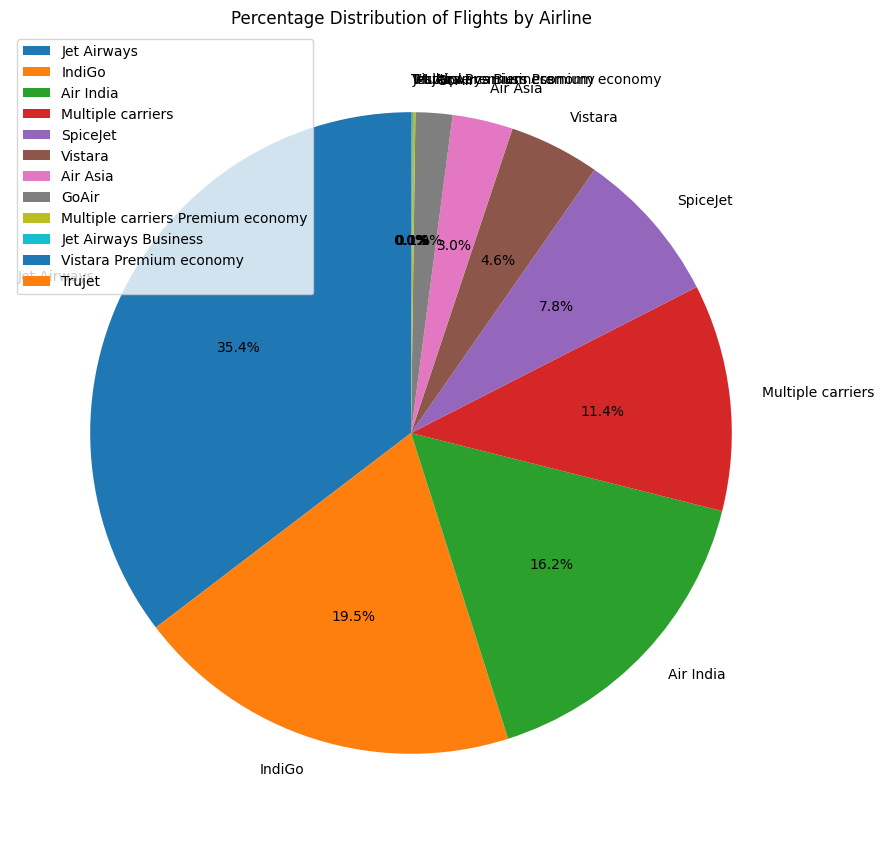

In [148]:
airline_count = df["Airline"].value_counts()
plt.figure(figsize=(9, 9))
plt.pie(airline_count,labels=airline_count.index,autopct="%1.1f%%",startangle=90)
plt.legend(loc="upper left")
plt.title("Percentage Distribution of Flights by Airline")
plt.tight_layout()
plt.show()

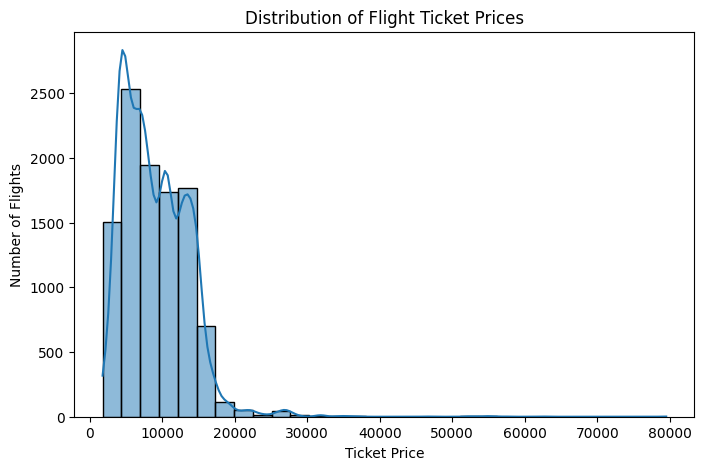

In [139]:
plt.figure(figsize=(8,5))
sns.histplot(data=df,x="Price",bins=30,kde=True)
plt.title("Distribution of Flight Ticket Prices")
plt.xlabel("Ticket Price")
plt.ylabel("Number of Flights")
plt.show()

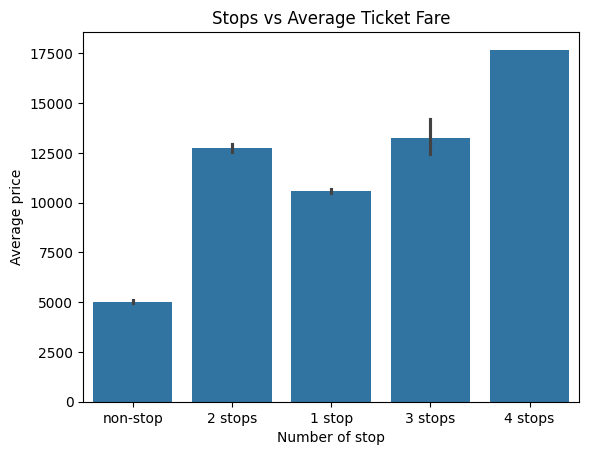

In [140]:
sns.barplot(data=df,x="Total_Stops",y="Price")
plt.title("Stops vs Average Ticket Fare")
plt.xlabel("Number of stop")
plt.ylabel("Average price")
plt.show()

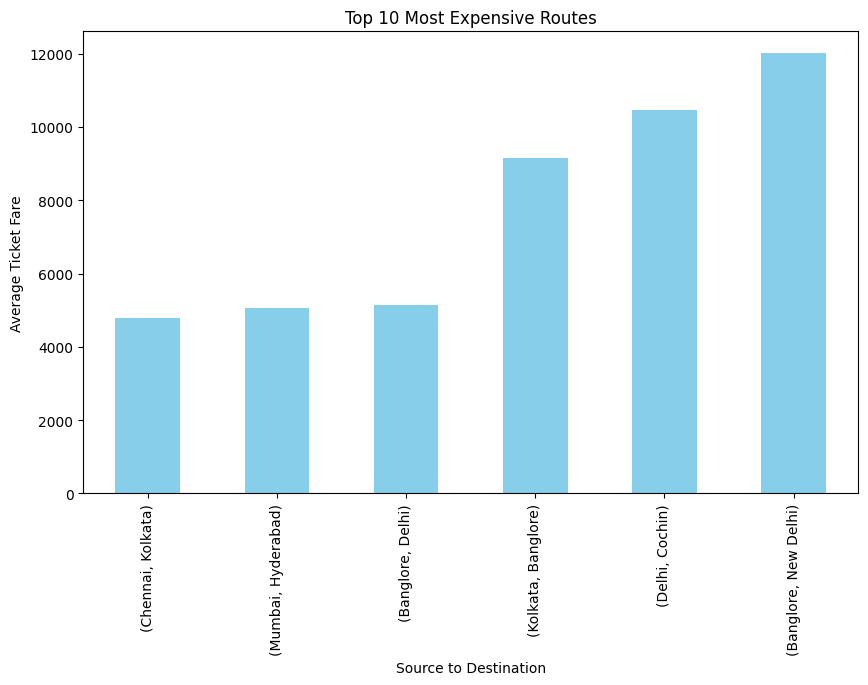

In [141]:
plt.figure(figsize=(10, 6))
route_fares.head(10).sort_values().plot(kind="bar",color="skyblue")
plt.title("Top 10 Most Expensive Routes")
plt.xlabel("Source to Destination")
plt.ylabel("Average Ticket Fare")
plt.show()

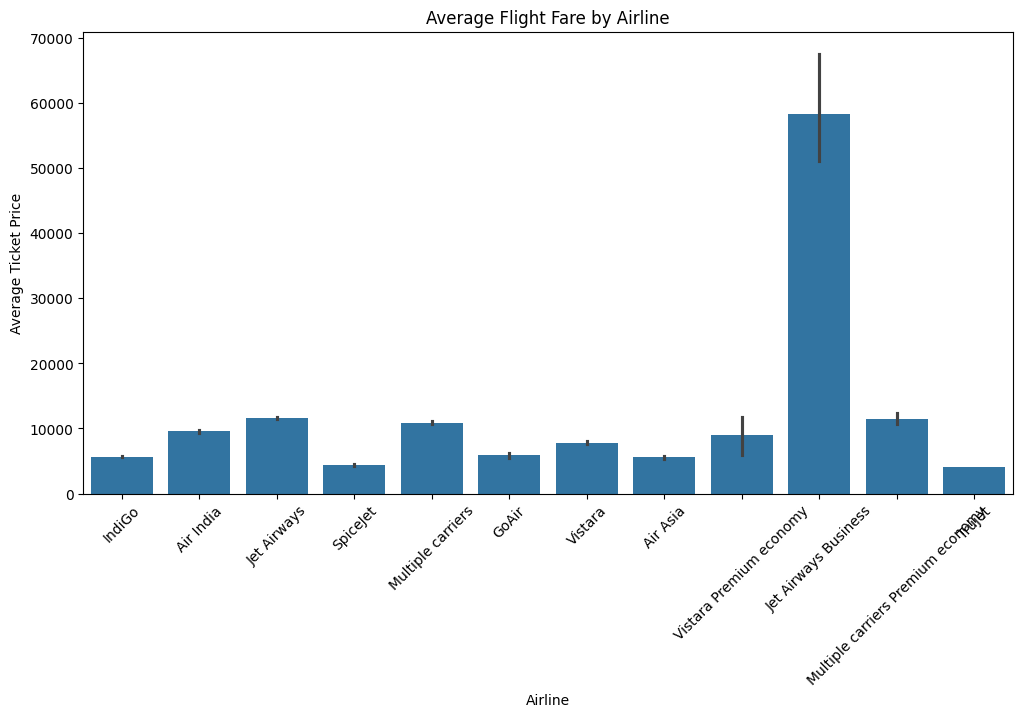

In [142]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df,x="Airline",y="Price")
plt.title("Average Flight Fare by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Ticket Price")
plt.xticks(rotation=45)
plt.show()

**OOPs** **Implementation**

In [143]:
class AirlineAnalysis:
  def __init__(self,df):
    self.df=df
  def average_price(self):
    return self.df["Price"].mean()
  def highest_price(self):
    return self.df["Price"].max()
  def lowest_price(self):
    return self.df["Price"].min()
analysis=AirlineAnalysis(df)
print("Average_price:",analysis.average_price())
print("highest_price:",analysis.highest_price())
print("lowest_price:",analysis.lowest_price())

Average_price: 9026.790288663735
highest_price: 79512
lowest_price: 1759


**Insights** & **Findings**

In [144]:

print("Cheapest airline:", airline_fares.idxmin())
print("Most expensive airline:", airline_fares.idxmax())
print("Most expensive route:",route_fares.head(1))
print("Average ticket price:", df["Price"].mean())
print("Highest ticket price:", df["Price"].max())
print("Lowest ticket price:", df["Price"].min())
print("Average fare by stops:",stops)

Cheapest airline: Trujet
Most expensive airline: Jet Airways Business
Most expensive route: Source    Destination
Banglore  New Delhi      12007.421225
Name: Price, dtype: float64
Average ticket price: 9026.790288663735
Highest ticket price: 79512
Lowest ticket price: 1759
Average fare by stops: Total_Stops
non-stop     5018.506763
1 stop      10594.123556
2 stops     12761.099393
3 stops     13260.674419
4 stops     17686.000000
Name: Price, dtype: float64
